The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


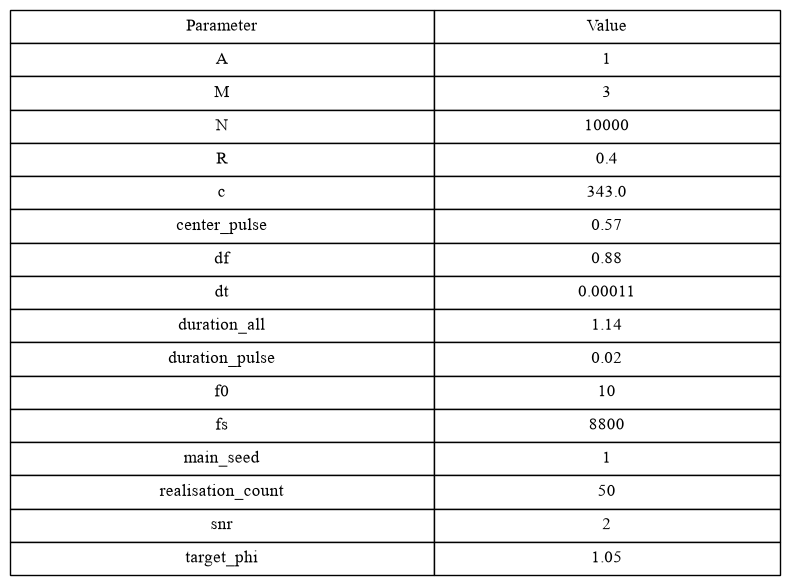

In [ ]:
"""В данном модуле рассматривается приближённая модель стиринг
сравниваются методы
Бартлетта и Кейпона для оценки азимута прихода сигнала в приближённой модели
"""

%load_ext autoreload
%autoreload 2

import numpy as np
import time
from src.experiments import (stat_vs_params, calculate_variance, calculate_stiring_matrix, )
from src.functions import (calculate_bartlett_values, 
                           calculate_capon_values, 
                           get_sin_signal, 
                           get_impulse_signal, calculate_stiring_matrix, calculate_complex_stiring_matrix)
from src.configs.config import init_rng, restart_rng
import src.configs.config as cfg
import src.configs.comon as comon
from src.plotting import plot_variance_vs_param, create_config_table
import os
origin_config = init_rng()
sin_signal = get_sin_signal
path = "attachment/images/report"
os.makedirs(path,exist_ok=True)

config_bartlett_aprox = dict(  # noqa: C408
                            energy_func=calculate_bartlett_values,
                            signal_func = sin_signal,
                            stat_func = calculate_variance,
                            stiring_func = calculate_stiring_matrix,
                            is_CRN = False)
config_capon_aprox = dict(  # noqa: C408
                            energy_func=calculate_capon_values,
                            signal_func = sin_signal,
                            stat_func = calculate_variance,
                            stiring_func = calculate_stiring_matrix,
                            is_CRN = False)
create_config_table(origin_config)

In [38]:
config_parametrs1 = restart_rng(origin_config)
config_parametrs2 = restart_rng(origin_config)
start_time = time.perf_counter()

parametr_config = dict(  # noqa: C408
    parametr_name = "target_phi",
    parametr_values = cfg.PHI_VALUES,
)        

var_bartlett_vs_phis = stat_vs_params(config_params = config_parametrs1,
                                    **parametr_config,
                                    **config_bartlett_aprox)
var_cap_vs_phis = stat_vs_params(config_params = config_parametrs2,
                                    **parametr_config,
                                    **config_capon_aprox)
end_time = time.perf_counter()
delta_time = end_time - start_time

(<Figure size 1400x1100 with 1 Axes>,
 <Axes: xlabel='Source azimuth $\\varphi_0$, deg', ylabel='$s_{\\varepsilon}^{2}$, deg$^2$'>)

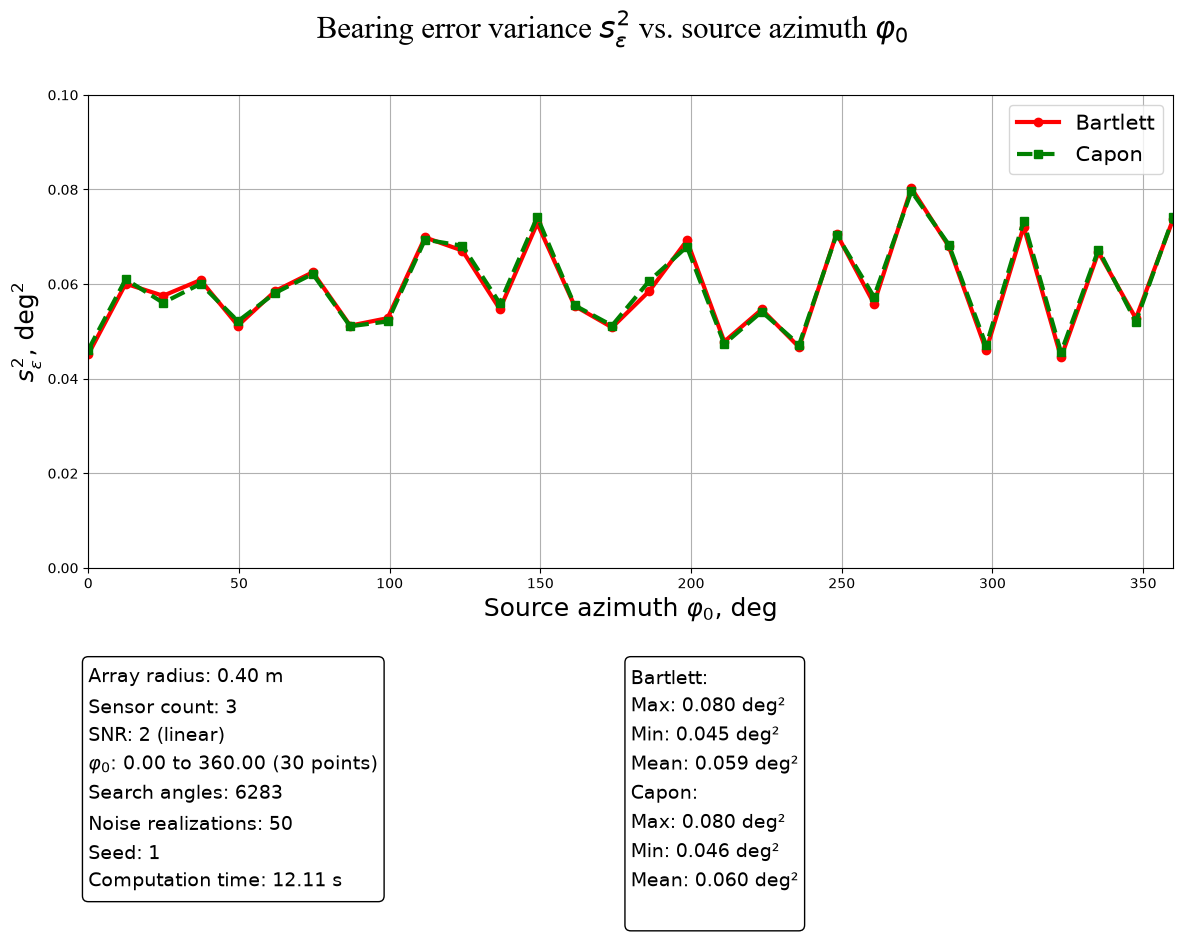

In [39]:
plot_variance_vs_param(dict_values = {"Bartlett": var_bartlett_vs_phis,
                                      "Capon": var_cap_vs_phis},
                       config_params = origin_config.copy(),
                       delta_time = delta_time,
                       ylim = (0.00*comon.CONST_RADIAN, 0.1*comon.CONST_RADIAN),
                       xlim = (0,360),
                       **parametr_config)

In [40]:
config_parametrs1 = restart_rng(origin_config)
config_parametrs2 = restart_rng(origin_config)
start_time = time.perf_counter()
    
parametr_config = dict(  # noqa: C408
    parametr_name = "snr",
    parametr_values = cfg.SNR_VALUES,
)        

var_bartlett_vs_snr = stat_vs_params(config_params=config_parametrs1,
                                   **parametr_config,
                                   **config_bartlett_aprox
                                   )
var_cap_vs_snr = stat_vs_params(config_params=config_parametrs2,
                                   **parametr_config,
                                   **config_capon_aprox
                                   )

end_time = time.perf_counter()
delta_time = end_time - start_time

(<Figure size 1400x1100 with 1 Axes>,
 <Axes: xlabel='SNR (linear)', ylabel='$s_{\\varepsilon}^{2}$, deg$^2$'>)

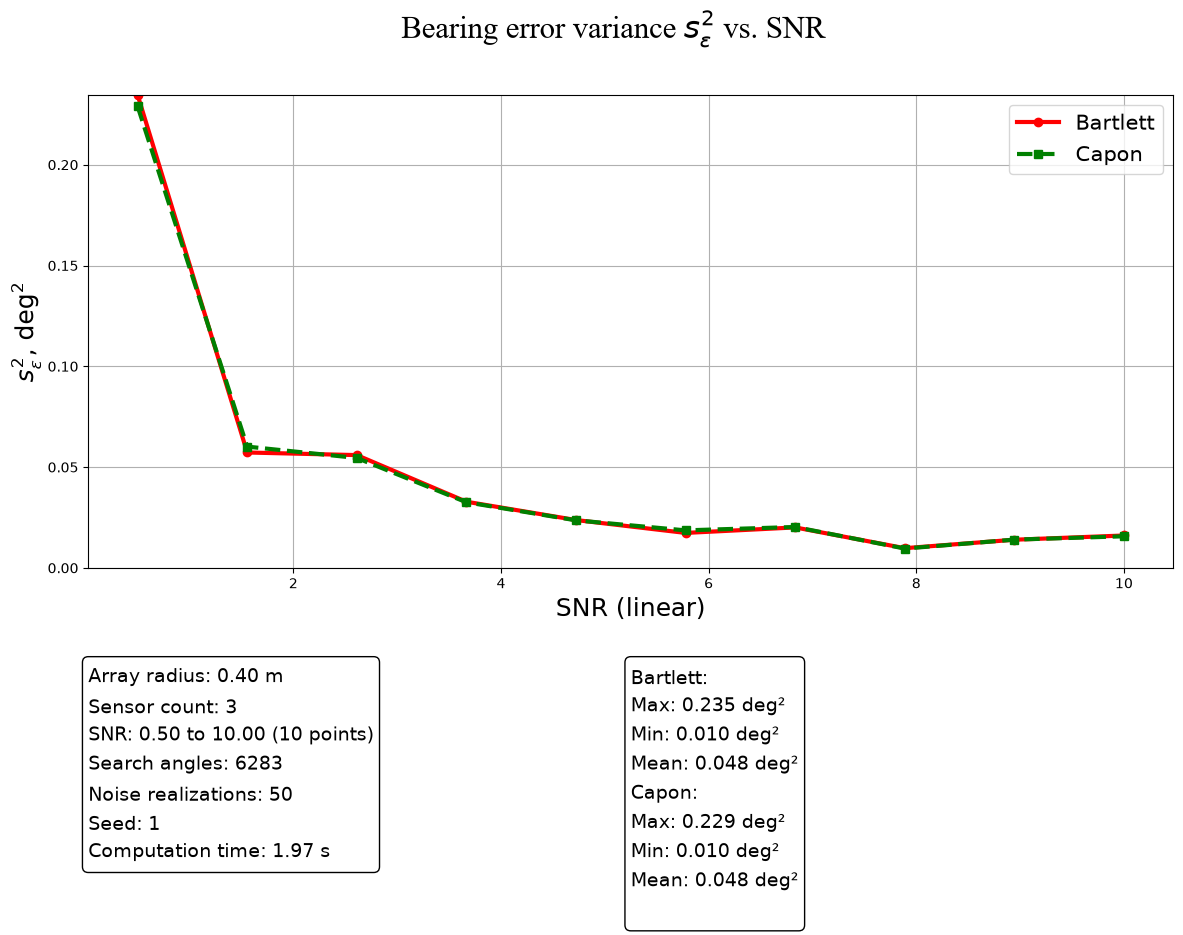

In [41]:
plot_variance_vs_param(dict_values = {"Bartlett": var_bartlett_vs_snr,
                                      "Capon": var_cap_vs_snr},
                       config_params = origin_config.copy(),
                       parametr_values = cfg.SNR_VALUES,
                       parametr_name = "snr",
                       delta_time = delta_time,
                       ylim = (0, max(max(var_bartlett_vs_snr),max(var_cap_vs_snr))))

In [42]:
config_parametrs1 = restart_rng(origin_config)
config_parametrs2 = restart_rng(origin_config)


start_time = time.perf_counter()

parametr_config = dict(  # noqa: C408
    parametr_name = "R",
    parametr_values = cfg.RADIUS_VALUES
)
var_bartlett_vs_r = stat_vs_params(config_params = config_parametrs1,
                              **parametr_config,
                              **config_bartlett_aprox)


var_cap_vs_r = stat_vs_params(config_params = config_parametrs2,
                                **parametr_config,
                                **config_capon_aprox
                                )

end_time = time.perf_counter()
delta_time = end_time - start_time

(<Figure size 1400x1100 with 1 Axes>,
 <Axes: xlabel='Array radius $R$, m', ylabel='$s_{\\varepsilon}^{2}$, deg$^2$'>)

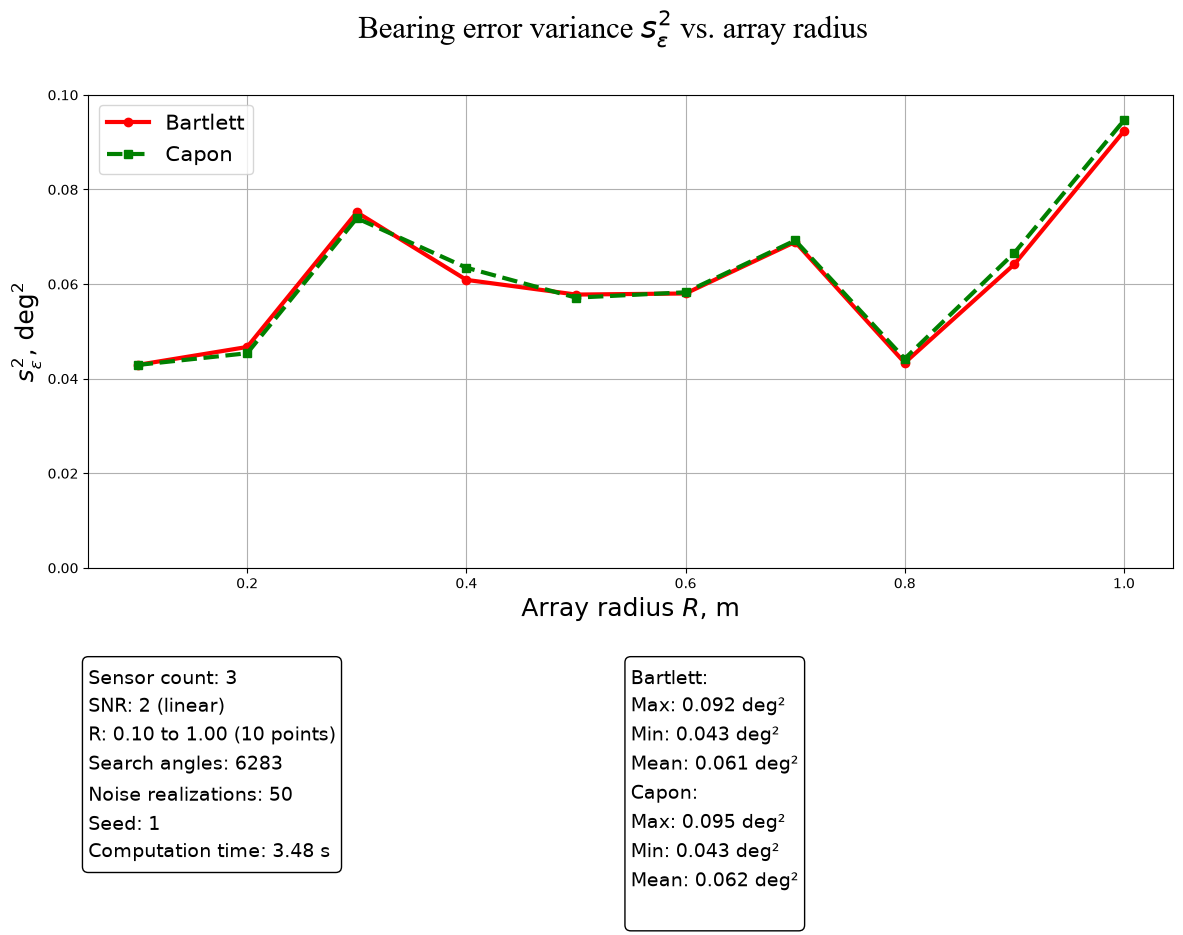

In [43]:
plot_variance_vs_param(dict_values = {"Bartlett": var_bartlett_vs_r,
                                      "Capon": var_cap_vs_r},
                       config_params = origin_config.copy(),
                       delta_time = delta_time,
                       ylim = (0, 0.1*comon.CONST_RADIAN),
                       **parametr_config)

In [44]:
config_parametrs1 = restart_rng(origin_config)
config_parametrs2 = restart_rng(origin_config)
start_time = time.perf_counter()

parametr_config = dict(  # noqa: C408
    parametr_name = "M",
    parametr_values = cfg.SENSOR_VALUES
)    

var_bartlett_vs_m = stat_vs_params(config_params = config_parametrs1,
                                 **parametr_config,
                                 **config_bartlett_aprox)


var_cap_vs_m = stat_vs_params(config_params = config_parametrs2,
                             **parametr_config,
                             **config_capon_aprox)

end_time = time.perf_counter()
delta_time = end_time - start_time

(<Figure size 1400x1100 with 1 Axes>,
 <Axes: xlabel='Sensor count $M$', ylabel='$s_{\\varepsilon}^{2}$, deg$^2$'>)

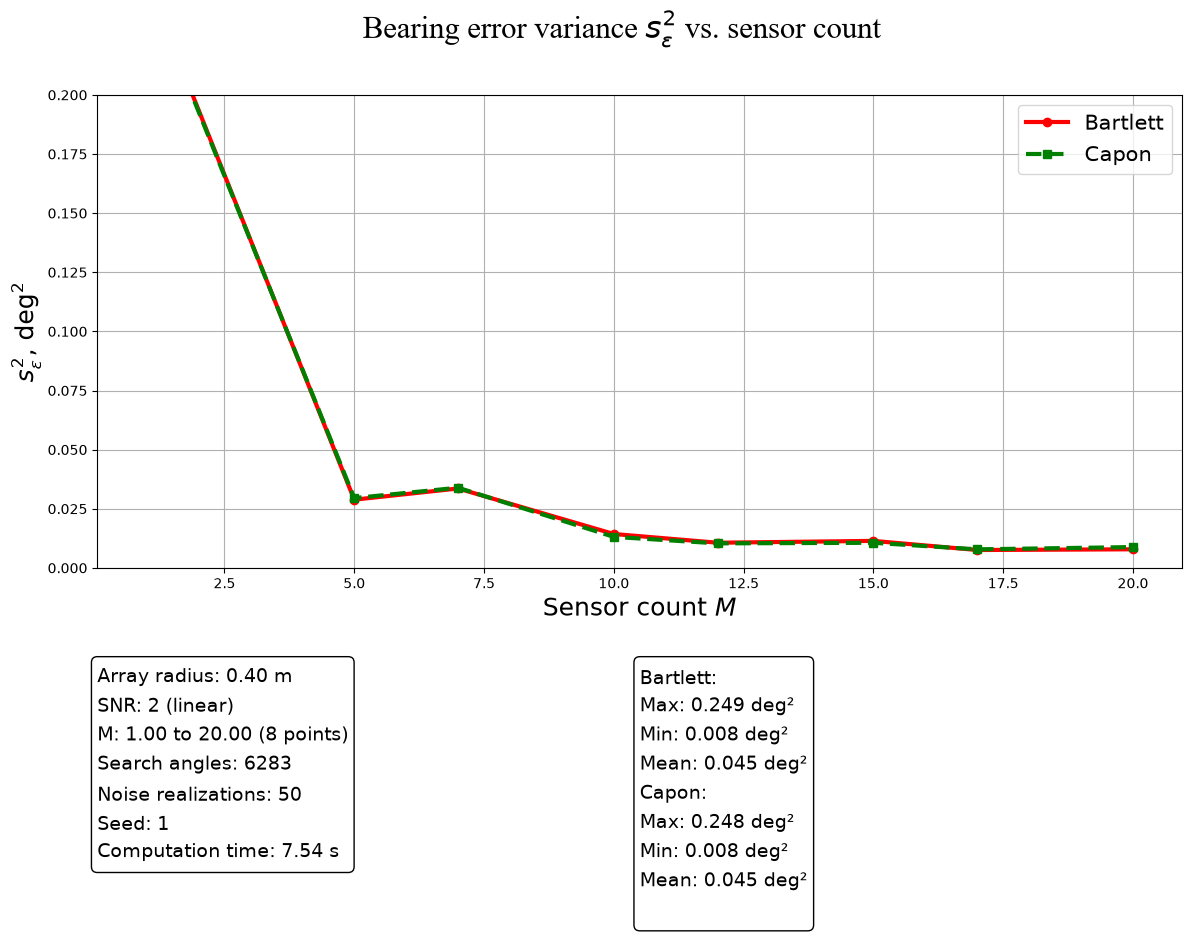

In [45]:
plot_variance_vs_param(dict_values = {"Bartlett": var_bartlett_vs_m,
                                      "Capon": var_cap_vs_m},
                       config_params = origin_config.copy(),
                       delta_time = delta_time,
                       ylim = (0, 0.2*comon.CONST_RADIAN),
                       **parametr_config)